In [7]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
#boston = load_boston()
boston = fetch_openml(name="boston", version=1, as_frame = True)
print(boston.keys())

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [8]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
SEED = 42
#X = boston.data
#y = boston.target
#for non numerical categorical data
X = boston.data.astype(float)
y = boston.target.astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= SEED)
# 3-Fold Cross-Validation
cross_validation_3 = KFold(n_splits=3, shuffle=True, random_state=SEED)
model_linear = LinearRegression()
# Calculate MSE for each fold
mse_linear = -cross_val_score(model_linear,X_train,y_train,cv=cross_validation_3,scoring="neg_mean_squared_error") #scikit reaturn negative scores
print("MSE for each fold:", mse_linear)
print("Mean MSE:", np.mean(mse_linear))
print("Standard Deviation:", np.std(mse_linear))

MSE for each fold: [23.72281731 29.42744455 17.76800373]
Mean MSE: 23.639421862092306
Standard Deviation: 4.760312047778979


The Linear Regression model was evaluated using 3-Fold Cross-Validation, where the training data was divided into three parts. The model was trained and validated three times, using a different fold for validation each time. The mean MSE was calculated to understand how well the model performed overall, while the standard deviation was used to check how much the results differed between folds. A lower mean MSE indicates that the model makes fewer prediction errors, whereas a smaller standard deviation shows that its performance is more consistent across the three folds.

In [28]:
alpha = 0.1
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_lasso = Lasso(alpha=0.1)
model_lasso.fit(X_train_scaled, y_train)
mse_lasso = -cross_val_score(model_lasso, X_train_scaled, y_train,cv=cross_validation_3,scoring="neg_mean_squared_error")
print("MSE for each fold:", mse_lasso)
print("Mean MSE:", np.mean(mse_lasso))
print("Standard Deviation:", np.std(mse_lasso))

MSE for each fold: [24.21982295 31.86795587 17.10602536]
Mean MSE: 24.397934728355043
Standard Deviation: 6.027848757645419


In [26]:
# Lasso Regression with alpha = 0.1
alpha = 0.1
model_lasso = make_pipeline(StandardScaler(),Lasso(alpha, max_iter=10000))
# Calculate MSE for each fold
mse_lasso = -cross_val_score(model_lasso, X_train, y_train,cv=cross_validation_3,scoring="neg_mean_squared_error")

print("MSE for each fold:", mse_lasso)
print("Mean MSE:", np.mean(mse_lasso))
print("Standard Deviation:", np.std(mse_lasso))

MSE for each fold: [24.21463861 31.85831285 17.09271756]
Mean MSE: 24.38855633858708
Standard Deviation: 6.029283352400821


The Lasso Regression model was evaluated using 3-Fold Cross-Validation with an alpha value of 0.1. Unlike Linear Regression, Lasso uses L1 regularization, which helps reduce the influence of less important features by shrinking their coefficients, sometimes even to zero. The model was trained and validated across three different folds, and the average MSE was calculated to measure its overall prediction error. This average MSE can then be compared with the Linear Regression results to see whether adding regularization helps the model make better predictions on unseen data.

In [30]:
#comparing linear regressiion and lasso model
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Lasso Regression"],
    "Fold 1 MSE": [mse_linear[0], mse_lasso[0]],
    "Fold 2 MSE": [mse_linear[1], mse_lasso[1]],
    "Fold 3 MSE": [mse_linear[2], mse_lasso[2]],
    "Mean MSE": [np.mean(mse_linear),np.mean(mse_lasso)],
    "Standard Deviation": [np.std(mse_linear),np.std(mse_lasso)]
})

print(comparison.round(4).to_string(index=False))

            Model  Fold 1 MSE  Fold 2 MSE  Fold 3 MSE  Mean MSE  Standard Deviation
Linear Regression     23.7228     29.4274      17.768   23.6394              4.7603
 Lasso Regression     24.2198     31.8680      17.106   24.3979              6.0278


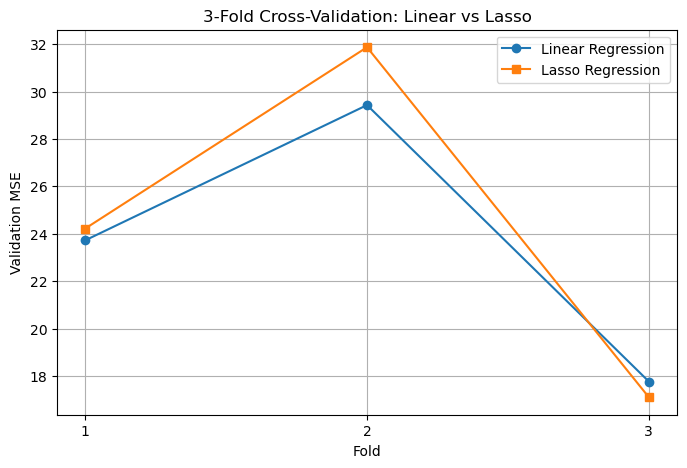

In [33]:
plt.figure(figsize=(8, 5))
folds = [1, 2, 3]
plt.plot(folds, mse_linear, marker="o",label="Linear Regression")
plt.plot(folds, mse_lasso, marker="s",label="Lasso Regression")
plt.xlabel("Fold")
plt.ylabel("Validation MSE")
plt.title("3-Fold Cross-Validation: Linear vs Lasso")
plt.xticks(folds)
plt.legend()
plt.grid()
plt.show()
